In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [7]:
#Load img
img=Image.open("avatar.jpg").convert("RGB")
img=img.resize((100,100))
img.show()

In [8]:
#convert img to pixel
pixels=np.array(img)/255.0
pixels=pixels.reshape(-1,3)

In [9]:
weights=np.random.rand(8,3)
for epoch in range(20):
    for pixel in pixels:
        distance=np.linalg.norm(weights-pixel,axis=1)
        bmu=np.argmin(distance)
        weights[bmu]+=0.1*(pixel-weights[bmu])

In [14]:
compressed=[]

for pixel in pixels:
    distance=np.linalg.norm(weights-pixel,axis=1)
    bmu=np.argmin(distance)
    compressed.append(weights[bmu])
    
compressed=np.array(compressed).reshape(100,100,3)
compressed=(compressed*255).astype(np.uint8)

(np.float64(-0.5), np.float64(99.5), np.float64(99.5), np.float64(-0.5))

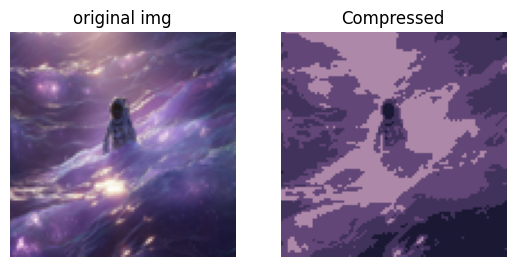

In [17]:
plt.subplot(1,2,1)
plt.imshow(img)
plt.title("original img")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(compressed)
plt.title("Compressed")
plt.axis("off")